# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :
- NIM   :
- Kelas : Reg B / Reg C *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 7   # 2 digit terakhir NIM: 07 -> 7

In [2]:
# Implementasi train_test_split (NumPy) seperti di materi
def train_test_split(X, y, test_size=0.2, random_state=None):
    """Acak indeks data lalu bagi menjadi data training dan testing."""
    rng = np.random.RandomState(random_state)
    n = len(X)
    indices = rng.permutation(n)
    n_test = int(round(n * test_size))
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


# ---------- Model regresi linear (NumPy) ----------
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                 # tambah kolom bias
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_, self.coef_ = theta[0], theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)"""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations

    def fit(self, X, y):
        n, d = X.shape
        self.intercept_, self.coef_ = 0.0, np.zeros(d)
        self.loss_history_ = []
        for _ in range(self.n_iter):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y
            self.loss_history_.append(np.mean(error ** 2))
            self.intercept_ -= self.lr * (2 / n) * np.sum(error)
            self.coef_ -= self.lr * (2 / n) * (X.T @ error)
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


# ---------- Model logistic regression (NumPy) ----------
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (loss = log loss)"""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations

    def fit(self, X, y):
        n, d = X.shape
        self.intercept_, self.coef_ = 0.0, np.zeros(d)
        self.loss_history_ = []
        eps = 1e-12
        for _ in range(self.n_iter):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            self.loss_history_.append(loss)
            error = p - y
            self.intercept_ -= self.lr * np.mean(error)
            self.coef_ -= self.lr * (X.T @ error) / n
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


# ---------- Metrik klasifikasi dasar ----------
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)


def confusion_matrix(y_true, y_pred):
    """Return [[TN, FP], [FN, TP]]"""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

In [3]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
print("Jumlah baris data:", len(df_ads))
df_ads.head()

Jumlah baris data: 40


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Shape X: (40, 1) | Shape y: (40,)


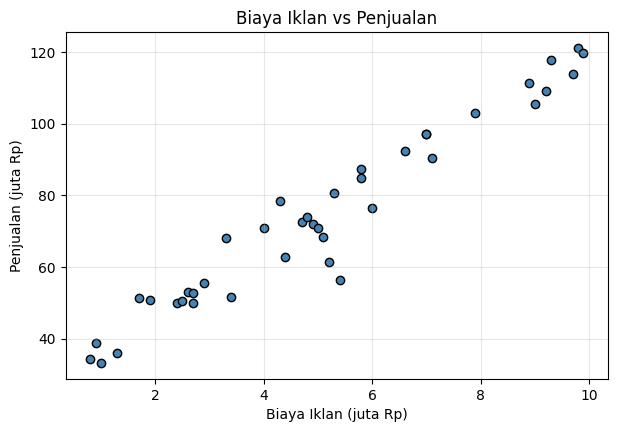

In [4]:
# Pisahkan X (2 dimensi) dan y
X = df_ads[["BiayaIklan"]].values      # shape (n, 1)
y = df_ads["Penjualan"].values         # shape (n,)
print("Shape X:", X.shape, "| Shape y:", y.shape)

# Scatter plot
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color="steelblue", edgecolor="k")
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [5]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [6]:
# Jawaban A3
lin_reg = LinearRegression().fit(X_train, y_train)
b = lin_reg.intercept_
m = lin_reg.coef_[0]
print(f"Intercept (b)  : {b:.4f}")
print(f"Koefisien (m)  : {m:.4f}")
print(f"Persamaan      : y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b)  : 28.2320
Koefisien (m)  : 9.2168
Persamaan      : y_hat = 28.2320 + 9.2168 * X


**Jawaban A3 (interpretasi):**

Persamaan regresi yang diperoleh: $\hat{y} = 28{,}2320 + 9{,}2168\,X$.

- **Koefisien $m = 9{,}2168$**: setiap kenaikan biaya iklan sebesar 1 juta Rp, penjualan per bulan rata-rata naik sekitar **9,22 juta Rp**.
- **Intercept $b = 28{,}2320$**: perkiraan penjualan ketika biaya iklan 0, yaitu penjualan dasar tanpa iklan. Karena biaya iklan terkecil di data adalah 0,8 juta, angka ini lebih tepat dibaca sebagai titik potong garis daripada fakta yang benar-benar teruji.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [7]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin_reg.predict(X_train)
y_pred_test = lin_reg.predict(X_test)

hasil_a4 = pd.DataFrame({
    "MAE":  [mae(y_train, y_pred_train),  mae(y_test, y_pred_test)],
    "MSE":  [mse(y_train, y_pred_train),  mse(y_test, y_pred_test)],
    "RMSE": [rmse(y_train, y_pred_train), rmse(y_test, y_pred_test)],
    "R2":   [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
}, index=["Training", "Testing"])
hasil_a4.round(4)

,MAE,MSE,RMSE,R2
Training,4.4449,36.4135,6.0344,0.9383
Testing,4.3539,36.3858,6.0321,0.9550


**Jawaban A4 (analisis):**

- **RMSE** training = 6,03 dan testing = 6,03 (juta Rp). Artinya prediksi penjualan model rata-rata meleset sekitar 6 juta Rp dari nilai sebenarnya, kira-kira 8% dari rata-rata penjualan (74,27 juta Rp).
- **$R^2$** training = 0,938 dan testing = 0,955. Jadi sekitar 94–96% variasi penjualan bisa dijelaskan oleh biaya iklan.
- Nilai di data testing hampir sama dengan data training (bahkan sedikit lebih baik), sehingga **tidak ada tanda overfitting**. Selisih kecil itu kemungkinan karena data testing hanya 8 titik, bukan karena model lebih bagus pada data baru.
- Kesimpulan: untuk model sederhana dengan satu fitur, model ini **sudah cukup baik**. Sisa galat sekitar 6 juta berasal dari faktor lain di luar biaya iklan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

=== learning rate = 0.001 ===
Intercept: 24.8354 | Koefisien: 9.7611 | Loss akhir: 38.8272
=== learning rate = 0.02 ===
Intercept: 28.2320 | Koefisien: 9.2168 | Loss akhir: 36.4135
=== learning rate = 0.1 ===
Intercept: nan | Koefisien: nan | Loss akhir: nan

Normal Equation -> Intercept: 28.2320 | Koefisien: 9.2168
Batas learning rate stabil (2 / lambda_max) = 0.0312
Pada lr = 0.1 loss pertama kali tidak finite (inf/NaN) di iterasi ke-207



/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
<cell>:38: RuntimeWarning: overflow encountered in square
<cell>:40: RuntimeWarning: overflow encountered in matmul
<cell>:40: RuntimeWarning: invalid value encountered in subtract


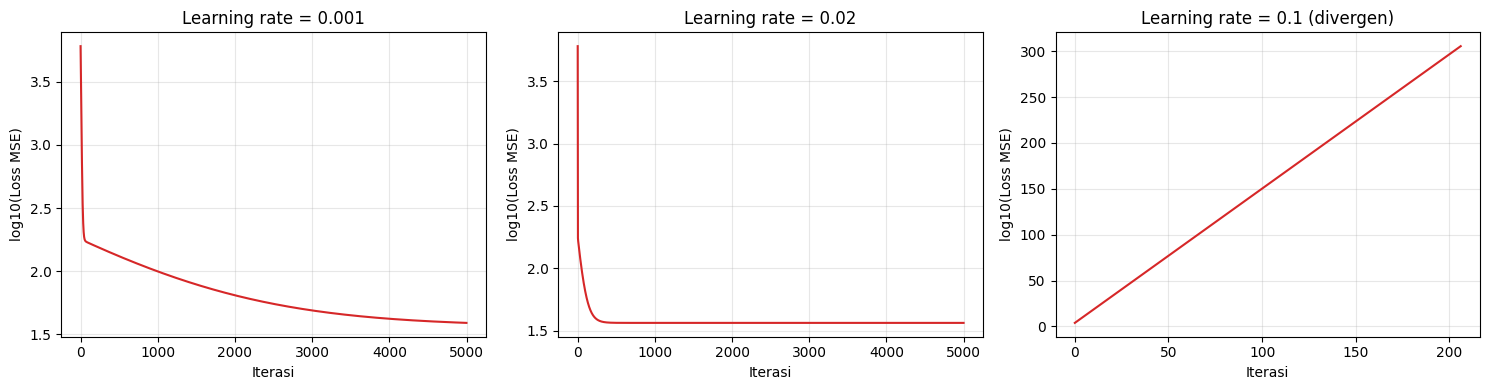

In [8]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}

for lr in learning_rates:
    print(f"=== learning rate = {lr} ===")
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = gd
    print(f"Intercept: {gd.intercept_:.4f} | Koefisien: {gd.coef_[0]:.4f} | Loss akhir: {gd.loss_history_[-1]:.4f}")

print()
print(f"Normal Equation -> Intercept: {lin_reg.intercept_:.4f} | Koefisien: {lin_reg.coef_[0]:.4f}")

# Batas learning rate agar GD stabil: lr < 2 / lambda_max, dengan lambda_max = eigenvalue terbesar Hessian MSE
Xb = np.c_[np.ones(len(X_train)), X_train]
lambda_max = np.linalg.eigvalsh(2 * Xb.T @ Xb / len(X_train)).max()
print(f"Batas learning rate stabil (2 / lambda_max) = {2 / lambda_max:.4f}")

# Iterasi pertama saat loss menjadi tidak hingga / NaN pada lr = 0.1
loss_div = np.array(gd_models[0.1].loss_history_)
iter_div = np.argmax(~np.isfinite(loss_div))
print(f"Pada lr = 0.1 loss pertama kali tidak finite (inf/NaN) di iterasi ke-{iter_div}")
print()

# Grafik loss vs iterasi (nilai inf/NaN tidak digambar)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    loss = np.array(gd_models[lr].loss_history_, dtype=float)
    loss[~np.isfinite(loss)] = np.nan
    with np.errstate(all="ignore"):
        ax.plot(np.log10(loss), color="tab:red")      # log10 agar nilai yang sangat besar tetap bisa digambar
    ax.set_title(f"Learning rate = {lr}" + (" (divergen)" if lr == 0.1 else ""))
    ax.set_xlabel("Iterasi")
    ax.set_ylabel("log10(Loss MSE)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

| Learning rate | Intercept | Koefisien | Loss akhir | Keterangan |
|---|---|---|---|---|
| 0,001 | 24,8354 | 9,7611 | 38,83 | terlalu lambat |
| 0,02 | 28,2320 | 9,2168 | 36,41 | pas |
| 0,1 | NaN | NaN | NaN | divergen |
| Normal equation | 28,2320 | 9,2168 | 36,41 | pembanding |

- **0,001 (terlalu lambat):** langkah tiap iterasi sangat kecil, sehingga setelah 5000 iterasi parameter belum sampai (intercept 24,84 vs 28,23; loss 38,83 vs 36,41). Kurva loss masih menurun dan belum mendatar.
- **0,02 (pas):** loss turun cepat lalu mendatar, dan hasilnya sama dengan normal equation sampai 4 angka desimal (loss akhir 36,4135 sama dengan loss training pada Soal A4).
- **0,1 (divergen):** learning rate terlalu besar, sehingga setiap langkah melompati titik minimum dan posisinya malah makin jauh. Batas learning rate yang stabil untuk data ini sekitar $2/\lambda_{max} = 0{,}0312$, sedangkan 0,1 jauh di atasnya. Loss membesar terus sampai pada iterasi ke-207 nilainya tidak lagi bisa direpresentasikan (inf/NaN).
- **Arti `RuntimeWarning: overflow`:** angka yang dihitung sudah melebihi batas terbesar tipe float64 (sekitar $10^{308}$). Ini bukan bug kode, tetapi tanda bahwa gradient descent divergen akibat learning rate yang terlalu besar.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

Biaya iklan  4.5 juta -> prediksi penjualan = 69.71 juta
Biaya iklan    7 juta -> prediksi penjualan = 92.75 juta
Biaya iklan   12 juta -> prediksi penjualan = 138.83 juta  <-- ekstrapolasi (di luar rentang data)

Rentang BiayaIklan pada data: 0.8 s/d 9.9


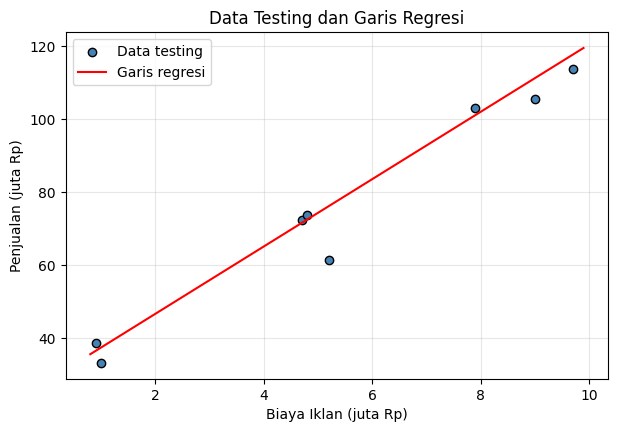

In [9]:
# Jawaban A6
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, color="steelblue", edgecolor="k", label="Data testing")
plt.plot(x_line, lin_reg.predict(x_line), color="red", label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Prediksi
for biaya in [4.5, 7, 12]:
    pred = lin_reg.predict(np.array([[biaya]]))[0]
    ket = "  <-- ekstrapolasi (di luar rentang data)" if biaya > X.max() else ""
    print(f"Biaya iklan {biaya:>4} juta -> prediksi penjualan = {pred:.2f} juta{ket}")
print(f"\nRentang BiayaIklan pada data: {X.min()} s/d {X.max()}")

**Jawaban A6 (analisis):**

Prediksi penjualan: biaya iklan 4,5 juta → **69,71 juta**; 7 juta → **92,75 juta**; 12 juta → **138,83 juta**.

Prediksi untuk 12 juta adalah **ekstrapolasi** karena rentang biaya iklan di data hanya 0,8–9,9 juta. Hasilnya (138,83 juta) bahkan lebih tinggi dari penjualan terbesar yang pernah ada di data (121,1 juta). Model hanya mempelajari pola linear di dalam rentang data, dan tidak ada jaminan pola itu tetap lurus di luar rentang tersebut. Bisa saja kenaikan penjualan mulai melambat (pasar jenuh, stok terbatas), sehingga prediksi ini **kurang dapat dipercaya** dan sebaiknya hanya dipakai sebagai perkiraan kasar. Sebaliknya, prediksi 4,5 dan 7 juta adalah interpolasi sehingga lebih dapat diandalkan, dengan kemungkinan meleset sekitar ±6 juta (RMSE).

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

In [10]:
# Jawaban B1
df_email = pd.read_csv("Email_Data.csv")
print("Jumlah baris data:", len(df_email))
print("\nJumlah per kelas:")
print(df_email["Spam"].value_counts().rename({0: "Bukan Spam (0)", 1: "Spam (1)"}))
df_email.head()

Jumlah baris data: 60

Jumlah per kelas:
Spam
Bukan Spam (0)    35
Spam (1)          25
Name: count, dtype: int64


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Shape X: (60, 2) | Shape y: (60,)


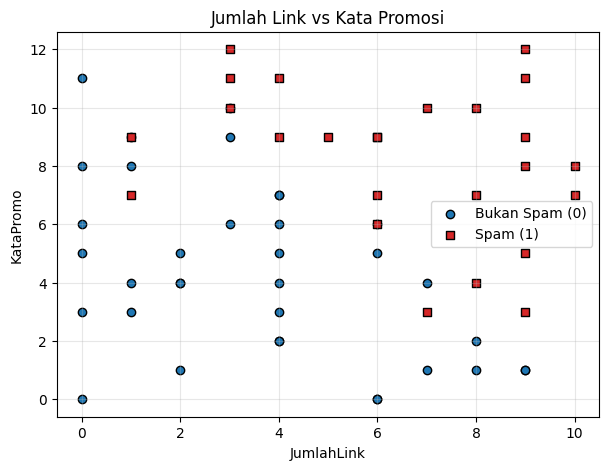

In [11]:
# Pisahkan X dan y
X_e = df_email[["JumlahLink", "KataPromo"]].values
y_e = df_email["Spam"].values
print("Shape X:", X_e.shape, "| Shape y:", y_e.shape)

# Scatter plot per kelas
plt.figure(figsize=(7, 5))
plt.scatter(X_e[y_e == 0, 0], X_e[y_e == 0, 1], color="tab:blue", edgecolor="k", label="Bukan Spam (0)")
plt.scatter(X_e[y_e == 1, 0], X_e[y_e == 1, 1], color="tab:red", edgecolor="k", marker="s", label="Spam (1)")
plt.title("Jumlah Link vs Kata Promosi")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Xe_train: (45, 2) | Xe_test: (15, 2)

Intercept (b)    : -12.3111
Koefisien m1 (JumlahLink): 1.0950
Koefisien m2 (KataPromo) : 0.9655
P(Spam) = sigmoid(-12.3111 + 1.0950 * JumlahLink + 0.9655 * KataPromo)
Log loss awal: 0.6931 | akhir: 0.2114
  Log loss iterasi   100: 0.5278
  Log loss iterasi  1000: 0.2859
  Log loss iterasi  5000: 0.2211
  Log loss iterasi 10000: 0.2114


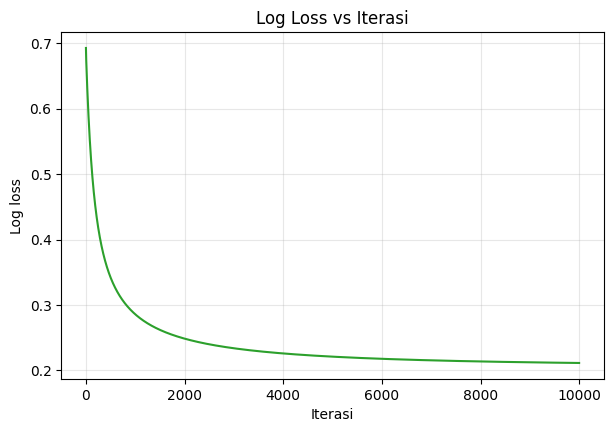

In [12]:
# Jawaban B2
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X_e, y_e, test_size=0.25, random_state=RANDOM_STATE)
print("Xe_train:", Xe_train.shape, "| Xe_test:", Xe_test.shape)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)
b0 = log_reg.intercept_
m1, m2 = log_reg.coef_
print(f"\nIntercept (b)    : {b0:.4f}")
print(f"Koefisien m1 (JumlahLink): {m1:.4f}")
print(f"Koefisien m2 (KataPromo) : {m2:.4f}")
print(f"P(Spam) = sigmoid({b0:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")
print(f"Log loss awal: {log_reg.loss_history_[0]:.4f} | akhir: {log_reg.loss_history_[-1]:.4f}")
for it in [100, 1000, 5000, 10000]:
    print(f"  Log loss iterasi {it:>5}: {log_reg.loss_history_[it - 1]:.4f}")

plt.figure(figsize=(7, 4.5))
plt.plot(log_reg.loss_history_, color="tab:green")
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.grid(alpha=0.3)
plt.show()

**Jawaban B2 (analisis):**

Persamaan: $P(\text{Spam}) = \sigma(-12{,}3111 + 1{,}0950\cdot\text{JumlahLink} + 0{,}9655\cdot\text{KataPromo})$. Kedua koefisien positif: setiap tambahan 1 link menaikkan log-odds spam sebesar 1,095 (odds sekitar 3 kali lipat) dan setiap tambahan 1 kata promosi menaikkan 0,9655 (odds sekitar 2,6 kali lipat).

Loss sudah **turun dan hampir stabil**: dari 0,6931 (tebakan acak) menjadi 0,5278 pada iterasi 100, 0,2859 pada iterasi 1000, 0,2211 pada iterasi 5000, dan 0,2114 pada iterasi 10000. Penurunan paling besar terjadi di awal lalu melandai; pada akhir iterasi masih ada penurunan yang sangat kecil.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [13]:
# Jawaban B3
def precision_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ye_pred = log_reg.predict(Xe_test)          # threshold 0.5
cm = confusion_matrix(ye_test, ye_pred)

print(f"Accuracy : {accuracy_score(ye_test, ye_pred):.4f}")
print(f"Precision: {precision_score(ye_test, ye_pred):.4f}")
print(f"Recall   : {recall_score(ye_test, ye_pred):.4f}")
print(f"F1-score : {f1_score(ye_test, ye_pred):.4f}")
print()
pd.DataFrame(cm, index=["Aktual Bukan Spam", "Aktual Spam"], columns=["Prediksi Bukan Spam", "Prediksi Spam"])

Accuracy : 0.8667
Precision: 1.0000
Recall   : 0.7143
F1-score : 0.8333



,Prediksi Bukan Spam,Prediksi Spam
Aktual Bukan Spam,8,0
Aktual Spam,2,5


**Jawaban B3 (analisis):**

Pada data testing (15 email): accuracy **0,8667** (13 dari 15 benar), precision **1,0**, recall **0,7143**, F1-score **0,8333**. Confusion matrix: TN = 8, FP = 0, FN = 2, TP = 5.

- **False Positive (FP):** email yang sebenarnya bukan spam, tetapi diprediksi spam (email sah masuk folder spam).
- **False Negative (FN):** email yang sebenarnya spam, tetapi diprediksi bukan spam (spam lolos ke inbox).
- Menurut saya **FP lebih merugikan**, karena email penting (tagihan, informasi kuliah, balasan lamaran kerja) bisa tidak terbaca pengguna. Spam yang lolos (FN) hanya mengganggu dan bisa dihapus manual. Model ini tidak punya FP sama sekali (precision 1,0), tetapi ada 2 FN.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = -(-12.3111 + 1.0950 * x1) / 0.9655
                 : x2 = 12.7505 + (-1.1341) * x1
Data testing yang salah diklasifikasikan:


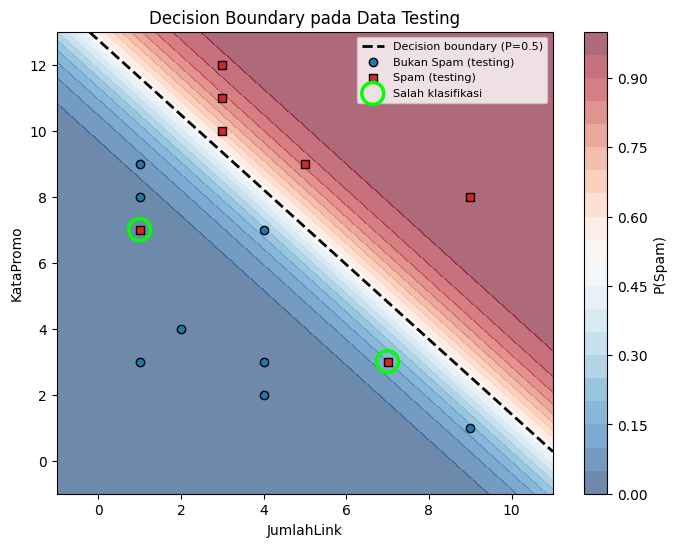

,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,7,3,1,0,0.1481
1,1,7,1,0,0.0115


In [14]:
# Jawaban B4
# Persamaan decision boundary: x2 = -(b + m1*x1) / m2
print(f"Decision boundary: x2 = -({b0:.4f} + {m1:.4f} * x1) / {m2:.4f}")
print(f"                 : x2 = {-b0/m2:.4f} + ({-m1/m2:.4f}) * x1")

# Grid untuk background probabilitas
x1_min, x1_max = X_e[:, 0].min() - 1, X_e[:, 0].max() + 1
x2_min, x2_max = X_e[:, 1].min() - 1, X_e[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
probs = log_reg.predict_proba(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

salah = ye_pred != ye_test      # data testing yang salah klasifikasi

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx1, xx2, probs, levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(cs, label="P(Spam)")
x_line = np.array([x1_min, x1_max])
plt.plot(x_line, -(b0 + m1 * x_line) / m2, "k--", linewidth=2, label="Decision boundary (P=0.5)")
plt.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], color="tab:blue", edgecolor="k", label="Bukan Spam (testing)")
plt.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], color="tab:red", edgecolor="k", marker="s", label="Spam (testing)")
plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], s=250, facecolors="none", edgecolors="lime", linewidths=2.5, label="Salah klasifikasi")
plt.xlim(x1_min, x1_max); plt.ylim(x2_min, x2_max)
plt.title("Decision Boundary pada Data Testing")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(loc="upper right", fontsize=8)
plt.show()

print("Data testing yang salah diklasifikasikan:")
salah_df = pd.DataFrame({
    "JumlahLink": Xe_test[salah, 0], "KataPromo": Xe_test[salah, 1],
    "Aktual": ye_test[salah], "Prediksi": ye_pred[salah],
    "P(Spam)": log_reg.predict_proba(Xe_test[salah]).round(4)})
salah_df

**Jawaban B4 (analisis):**

Decision boundary: $x_2 = -\dfrac{-12{,}3111 + 1{,}0950\,x_1}{0{,}9655} = 12{,}7505 - 1{,}1341\,x_1$. Karena kedua koefisien hampir sama besar, garisnya kira-kira $x_1 + x_2 \approx 11$: email di atas garis diprediksi spam dan di bawahnya bukan spam.

Ada **2 data testing yang salah klasifikasi** (dilingkari hijau): email dengan (JumlahLink, KataPromo) = (7, 3) dengan P(Spam) = 0,148 dan (1, 7) dengan P(Spam) = 0,012. Keduanya sebenarnya spam, tetapi jumlah link dan kata promonya tidak terlalu banyak (total 10 dan 8, di bawah sekitar 11), sehingga jatuh di bawah garis dan diprediksi bukan spam. Ini batasan model linear: boundary-nya hanya berupa garis lurus, dan spam yang "tampak biasa" sulit ditangkap.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [15]:
# Jawaban B5
proba_test = log_reg.predict_proba(Xe_test)
baris = []
for th in [0.3, 0.5, 0.7]:
    pred = (proba_test >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(ye_test, pred).ravel()
    baris.append({"Threshold": th, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                  "Precision": precision_score(ye_test, pred),
                  "Recall": recall_score(ye_test, pred),
                  "Accuracy": accuracy_score(ye_test, pred)})
tabel_threshold = pd.DataFrame(baris).set_index("Threshold")
tabel_threshold.round(4)

,TN,FP,FN,TP,Precision,Recall,Accuracy
Threshold,,,,,,,
0.3,8,0,2,5,1.0,0.7143,0.8667
0.5,8,0,2,5,1.0,0.7143,0.8667
0.7,8,0,3,4,1.0,0.5714,0.8000


**Jawaban B5 (analisis):**

- Menurunkan threshold membuat lebih banyak email diprediksi spam, sehingga **recall naik** tetapi **precision cenderung turun** (FP bertambah). Menaikkan threshold bekerja sebaliknya: **precision naik** tetapi **recall turun** (FN bertambah).
- Pada data ini, threshold 0,3 memberi hasil yang sama dengan 0,5 (precision 1,0; recall 0,7143), karena dua spam yang salah diprediksi punya probabilitas jauh di bawah 0,3 (0,148 dan 0,012). Pada threshold 0,7 recall turun menjadi 0,5714 (FN bertambah jadi 3) dan accuracy turun menjadi 0,80, sedangkan precision tetap 1,0 karena memang tidak ada FP.
- **Threshold pilihan saya: 0,5.** Berdasarkan Soal B3, FP lebih merugikan. Precision sudah 1,0 pada threshold 0,5, sehingga menaikkan ke 0,7 hanya membuat lebih banyak spam lolos tanpa keuntungan. Menurunkan ke 0,3 tidak menambah recall pada data testing dan hanya menambah risiko FP pada email baru. Catatan: data testing hanya 15 email, jadi kesimpulan ini belum kuat.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [16]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.5   # threshold pilihan dari Soal B5
email_baru = pd.DataFrame({"Email": ["E1", "E2", "E3", "E4"],
                           "JumlahLink": [1, 5, 9, 2],
                           "KataPromo": [2, 6, 10, 11]})
X_baru = email_baru[["JumlahLink", "KataPromo"]].values
email_baru["P(Spam)"] = log_reg.predict_proba(X_baru).round(4)
email_baru["Prediksi"] = np.where(email_baru["P(Spam)"] >= THRESHOLD_PILIHAN, "Spam", "Bukan Spam")
email_baru

,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0001,Bukan Spam
1,E2,5,6,0.2606,Bukan Spam
2,E3,9,10,0.9993,Spam
3,E4,2,11,0.6224,Spam


**Catatan B6:** dengan threshold 0,5, E1 (P = 0,0001) dan E2 (P = 0,2606) diprediksi **Bukan Spam**, sedangkan E3 (P = 0,9993) dan E4 (P = 0,6224) diprediksi **Spam**. E3 sangat yakin spam karena link dan kata promonya banyak. E4 termasuk batas: link sedikit (2) tetapi kata promo banyak (11), sehingga probabilitasnya hanya 0,62. Jika threshold dinaikkan ke 0,7, E4 akan berubah menjadi Bukan Spam.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena keluaran akhirnya adalah kelas (misalnya Spam atau Bukan Spam), bukan angka kontinu. Model menghitung kombinasi linear $z = b + m_1x_1 + m_2x_2$, lalu fungsi **sigmoid** $\sigma(z) = 1/(1+e^{-z})$ mengubah $z$ yang bisa bernilai berapa saja menjadi angka antara 0 dan 1 yang ditafsirkan sebagai probabilitas kelas 1. Probabilitas itu kemudian dibandingkan dengan threshold (biasanya 0,5) untuk menentukan kelas. Kata "regression" ada karena bagian dalamnya adalah regresi linear terhadap log-odds.

**Jawaban C2:**
Normal equation menghitung parameter langsung dalam satu rumus $\theta = (X^TX)^{-1}X^Ty$, tanpa learning rate dan tanpa iterasi, tetapi mahal karena ada invers matriks dan bermasalah jika $X^TX$ singular. Gradient descent memperbarui parameter sedikit demi sedikit mengikuti arah turunnya loss, sehingga perlu memilih learning rate dan jumlah iterasi (lihat Soal A5: terlalu kecil lambat, terlalu besar divergen). Gradient descent sebaiknya dipakai ketika jumlah fitur atau data sangat besar, atau ketika modelnya tidak punya solusi rumus tertutup seperti Logistic Regression dan neural network.

**Jawaban C3:**
Model dilatih menggunakan data training, sehingga skor pada data itu cenderung terlalu optimis karena model sudah "melihat" jawabannya. Data testing belum pernah dilihat model, jadi skornya menggambarkan kemampuan model pada data baru. **Overfitting** terjadi ketika model terlalu menyesuaikan diri dengan data training (termasuk noise) sehingga skor training bagus tetapi skor testing jauh lebih buruk. Pada tugas ini $R^2$ training (0,938) dan testing (0,955) mirip, jadi tidak ada tanda overfitting.

**Jawaban C4:**
Linear Regression memprediksi angka kontinu, sehingga wajar mengukur galat sebagai kuadrat selisih nilai prediksi dan nilai asli (MSE), dan loss ini berbentuk cekung ke atas (konveks) sehingga mudah dioptimasi. Logistic Regression menghasilkan probabilitas 0–1 untuk label 0/1, dan log loss berasal dari prinsip maximum likelihood untuk data biner. Log loss memberi hukuman sangat besar untuk prediksi yang yakin tetapi salah, dan tetap konveks, sedangkan MSE yang dikombinasikan dengan sigmoid menjadi tidak konveks dan gradiennya mengecil ketika prediksi sangat salah.

**Jawaban C5:**
Penyebab utamanya adalah `random_state` yang berbeda (diambil dari NIM masing-masing), sehingga pembagian data training dan testing berbeda. Model dilatih dan diuji pada potongan data yang berbeda, jadi koefisien, akurasi, dan metrik lainnya ikut berbeda walaupun dataset dan algoritmanya sama. Dataset yang kecil (40 dan 60 baris) membuat hasil lebih sensitif terhadap pembagian ini. Parameter awal pada implementasi ini selalu nol, jadi faktor pembedanya terutama pembagian data.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [17]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# --- Linear Regression ---
sk_lin = SkLinearRegression().fit(X_train, y_train)
print("== Linear Regression ==")
print(f"Implementasi sendiri : intercept={lin_reg.intercept_:.6f}, koef={lin_reg.coef_[0]:.6f}")
print(f"scikit-learn         : intercept={sk_lin.intercept_:.6f}, koef={sk_lin.coef_[0]:.6f}")
print(f"R2 test (sendiri / sklearn): {r2_score(y_test, lin_reg.predict(X_test)):.4f} / {r2_score(y_test, sk_lin.predict(X_test)):.4f}")

# --- Logistic Regression ---
sk_log_default = SkLogisticRegression().fit(Xe_train, ye_train)                       # default: L2, C=1.0
sk_log_nopen = SkLogisticRegression(C=1e10, max_iter=100000).fit(Xe_train, ye_train)      # C sangat besar = hampir tanpa regularisasi

print("\n== Logistic Regression ==")
def log_loss(y_true, p):
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

hasil = pd.DataFrame({
    "Intercept": [log_reg.intercept_, sk_log_default.intercept_[0], sk_log_nopen.intercept_[0]],
    "m1 (JumlahLink)": [log_reg.coef_[0], sk_log_default.coef_[0][0], sk_log_nopen.coef_[0][0]],
    "m2 (KataPromo)": [log_reg.coef_[1], sk_log_default.coef_[0][1], sk_log_nopen.coef_[0][1]],
    "Log loss train": [log_loss(ye_train, log_reg.predict_proba(Xe_train)),
                       log_loss(ye_train, sk_log_default.predict_proba(Xe_train)[:, 1]),
                       log_loss(ye_train, sk_log_nopen.predict_proba(Xe_train)[:, 1])],
    "Accuracy test": [accuracy_score(ye_test, log_reg.predict(Xe_test)),
                      accuracy_score(ye_test, sk_log_default.predict(Xe_test)),
                      accuracy_score(ye_test, sk_log_nopen.predict(Xe_test))],
}, index=["Implementasi sendiri", "sklearn (default, L2 C=1)", "sklearn (C=1e10, tanpa regularisasi)"])
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
hasil.round(4)

== Linear Regression ==
Implementasi sendiri : intercept=28.231952, koef=9.216840
scikit-learn         : intercept=28.231952, koef=9.216840
R2 test (sendiri / sklearn): 0.9550 / 0.9550

== Logistic Regression ==


,Intercept,m1 (JumlahLink),m2 (KataPromo),Log loss train,Accuracy test
Implementasi sendiri,-12.3111,1.0950,0.9655,0.2114,0.8667
"sklearn (default, L2 C=1)",-11.7837,1.0405,0.9234,0.2132,0.8667
"sklearn (C=1e10, tanpa regularisasi)",-15.7375,1.4076,1.2299,0.2068,0.8667


**Jawaban Bonus (analisis):**

- **Linear Regression:** hasilnya **identik** (intercept 28,231952 dan koefisien 9,216840, $R^2$ testing 0,9550), karena scikit-learn juga menyelesaikan least squares secara eksak tanpa regularisasi, sama dengan normal equation kita.
- **Logistic Regression:** koefisien **berbeda**. Penyebab pertama: `LogisticRegression` scikit-learn secara default memakai **regularisasi L2 dengan `C = 1.0`**, yang menyusutkan koefisien (m1 1,0405 dan m2 0,9234 vs 1,0950 dan 0,9655 pada implementasi kita yang tanpa regularisasi). Penyebab kedua: ketika regularisasi dibuat hampir hilang (`C = 1e10`), koefisien scikit-learn (-15,74; 1,41; 1,23) masih lebih besar dari milik kita. Hal ini karena gradient descent kita berhenti di 10000 iterasi dengan log loss training 0,2114, sedangkan solver scikit-learn sampai ke optimum (log loss 0,2068). Data hampir bisa dipisahkan sehingga koefisien optimal membesar dan gradient descent menuju ke sana dengan lambat.
- Walaupun koefisiennya berbeda, **accuracy pada data testing sama (0,8667)** untuk ketiganya, sehingga perbedaan tersebut tidak mengubah prediksi pada data testing.